# 第 5 章 蒙特卡罗优化方法 — 代码实验

对照教材：Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》第 5 章（§5.1–5.5）。

8 个实验，输出图 `out-5-M.png`。随机种子 2028。

In [1]:
# ===== 公共设置 =====
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import comb, log, factorial

rng = np.random.default_rng(2028)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch05")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 Sandia 山 2-bit 退火（书习题 1）

f(0)=−1, f(1)=1, f(2)=1/2, f(3)=0（全局最小 −1 在 0，被 1 的峰挡住）。逆对数冷却 T=1/log(t+1)；
验证转移矩阵，并统计从 x=3 出发找到全局最优所需迭代（书：像 St. Petersburg 的重尾）。

T=0.1 时转移矩阵（行=x，列=y）：
[[1.    0.    0.    0.   ]
 [0.5   0.    0.5   0.   ]
 [0.    0.003 0.497 0.5  ]
 [0.    0.    0.003 0.997]]


2000 次退火：找到全局最优比例 = 0.704，成功所需迭代中位 = 34


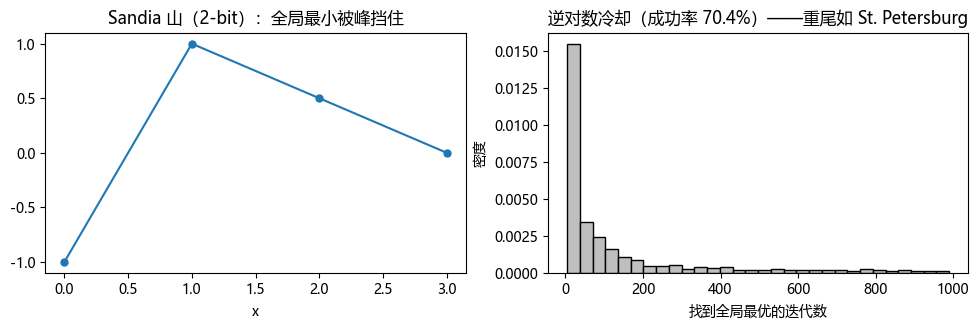

In [2]:
# ===== 书习题 1 Sandia =====
fS = np.array([-1.0, 1.0, 0.5, 0.0])
def sa_sandia(Tfun, maxit=1000):
    x = 3; t = 1
    while x != 0 and t <= maxit:
        y = x + (1 if rng.random() < 0.5 else -1)
        if 0 <= y <= 3:
            T = Tfun(t)
            if rng.random() < min(1, np.exp(-(fS[y]-fS[x])/T)): x = y
        t += 1
    return t
# 转移矩阵（t 大时 T 小）：从 i 到 j 一步的接受概率
Tt = 0.1
Pm = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        if abs(i-j) == 1:
            Pm[i, j] = 0.5*min(1, np.exp(-(fS[j]-fS[i])/Tt))
    Pm[i, i] = 1 - Pm[i].sum()
print("T=0.1 时转移矩阵（行=x，列=y）：")
print(np.round(Pm, 3))

times = [sa_sandia(lambda t: 1.0/log(t+1)) for _ in range(2000)]
times = np.array(times)
print(f"2000 次退火：找到全局最优比例 = {np.mean(times<=1000):.3f}，"
      f"成功所需迭代中位 = {np.median(times[times<=1000]):.0f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
xs = np.arange(4)
ax[0].plot(xs, fS, "o-", ms=5)
ax[0].set_title("Sandia 山（2-bit）：全局最小被峰挡住"); ax[0].set_xlabel("x")
succ = times[times <= 1000]
ax[1].hist(succ, bins=30, color="0.75", edgecolor="k", density=True)
ax[1].set_xlabel("找到全局最优的迭代数"); ax[1].set_ylabel("密度")
ax[1].set_title(f"逆对数冷却（成功率 {np.mean(times<=1000):.1%}）——重尾如 St. Petersburg")
plt.tight_layout(); save(fig, "out-5-1.png"); plt.show()

## 实验 2 冷却日程对比（书 §5.1 式 (5.3)(5.4)）

多极小一维函数：逆对数 vs 几何冷却各 12 条轨迹。几何更快但需标定；相变点附近都出现骤降。

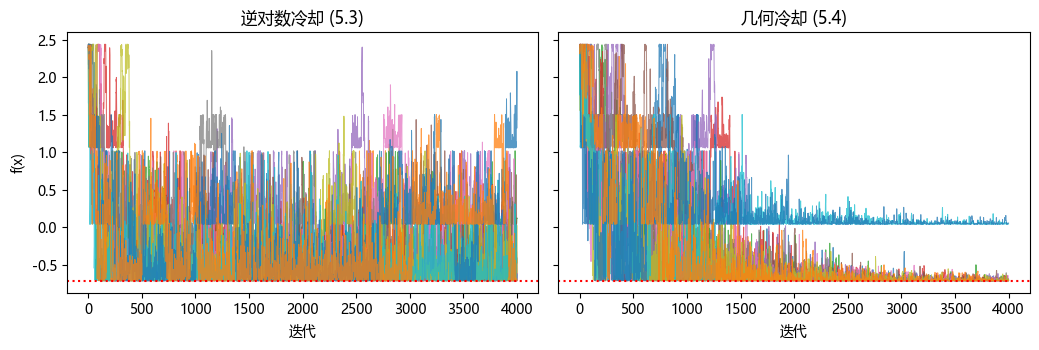

全局最优 ≈ -0.7160（x*≈1.44）


In [3]:
# ===== 书 §5.1 冷却 =====
def fmult(x):   # 多极小目标（最小化）
    return np.cos(2.1*x)*np.exp(-x/8) + 0.05*x + 0.02*x*x
xs = np.linspace(0, 10, 800)
def sa_run(cool, n=4000, x0=9.0):
    x = x0; traj = [fmult(x)]
    for t in range(1, n+1):
        y = x + rng.normal(0, 0.4)
        if 0 <= y <= 10:
            T = cool(t)
            if rng.random() < min(1, np.exp(-(fmult(y)-fmult(x))/T)): x = y
        traj.append(fmult(x))
    return np.array(traj)
logc = lambda t: 3.0/log(t+1)                # 逆对数
geoc = lambda t: 2.0*(0.9985**t) + 0.02      # 几何
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
for a, cool, lab in [(ax[0], logc, "逆对数冷却 (5.3)"), (ax[1], geoc, "几何冷却 (5.4)")]:
    for _ in range(12):
        a.plot(sa_run(cool), lw=0.7, alpha=0.75)
    a.set_title(lab); a.set_xlabel("迭代")
ax[0].set_ylabel("f(x)")
for a in ax: a.axhline(fmult(xs).min(), ls=":", color="r")
plt.tight_layout(); save(fig, "out-5-2.png"); plt.show()
print(f"全局最优 ≈ {fmult(xs).min():.4f}（x*≈{xs[fmult(xs).argmin()]:.2f}）")

## 实验 3 16 城 TSP（书 §5.2 PPR；习题 8 数据）

SA + 路径部分反转 + 几何冷却。书给出 16 城坐标与 (16−1)!/2 ≈ 6.5×10¹¹ 条 tour。

6 次 run 的 tour 长度: [231.6 231.6 231.6 231.6 231.6 231.6]（最优 231.6）；穷举下界不可行，解空间 (16−1)!/2 = 653,837,184,000


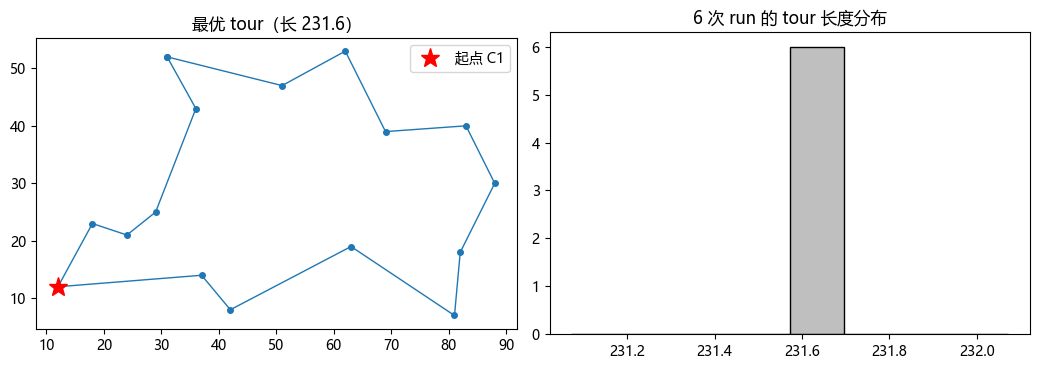

In [4]:
# ===== 书习题 8 TSP16 =====
cities = np.array([(12,12),(18,23),(24,21),(29,25),(31,52),(36,43),(37,14),
                   (42,8),(51,47),(62,53),(63,19),(69,39),(81,7),(82,18),
                   (83,40),(88,30)], float)
D = np.linalg.norm(cities[:, None]-cities[None, :], axis=2)
def tour_len(t):
    return sum(D[t[k], t[(k+1) % len(t)]] for k in range(len(t)))
def ppr(t):
    k1, k2 = sorted(rng.choice(len(t), 2, replace=False))
    return np.concatenate([t[:k1], t[k1:k2+1][::-1], t[k2+1:]])
def sa_tsp(n_iter=200_000):
    t = np.concatenate([[0], rng.permutation(np.arange(1, 16))])
    E = tour_len(t); best, bt = E, t.copy()
    for it in range(1, n_iter+1):
        T = 2000*0.99996**it + 1.0
        t2 = ppr(t); E2 = tour_len(t2)
        if E2 < E or rng.random() < np.exp(-(E2-E)/T):
            t, E = t2, E2
        if E < best: best, bt = E, t.copy()
    return best, bt
bests = []
for run in range(6):
    b, bt = sa_tsp()
    bests.append(b)
bests = np.array(bests)
b, bt = sa_tsp()
print(f"6 次 run 的 tour 长度: {bests.round(1)}（最优 {bests.min():.1f}）；"
      f"穷举下界不可行，解空间 (16−1)!/2 = {int(factorial(15)/2):,}")
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
tt = np.concatenate([bt, bt[:1]])
ax[0].plot(cities[tt, 0], cities[tt, 1], "o-", ms=4, lw=1)
ax[0].plot(cities[0, 0], cities[0, 1], "r*", ms=14, label="起点 C1")
ax[0].set_title(f"最优 tour（长 {b:.1f}）"); ax[0].legend(); ax[0].set_aspect("equal")
ax[1].hist(bests, bins=8, color="0.75", edgecolor="k")
ax[1].set_title("6 次 run 的 tour 长度分布")
plt.tight_layout(); save(fig, "out-5-3.png"); plt.show()

## 实验 4 二进制 GA 解 12 项 Shekel（书 §5.4，Table 5.1，Fig 5.6/5.7）

10 位编码 x=10c/1023，种群 12，轮盘赌 + 单点交叉 + 位变异。

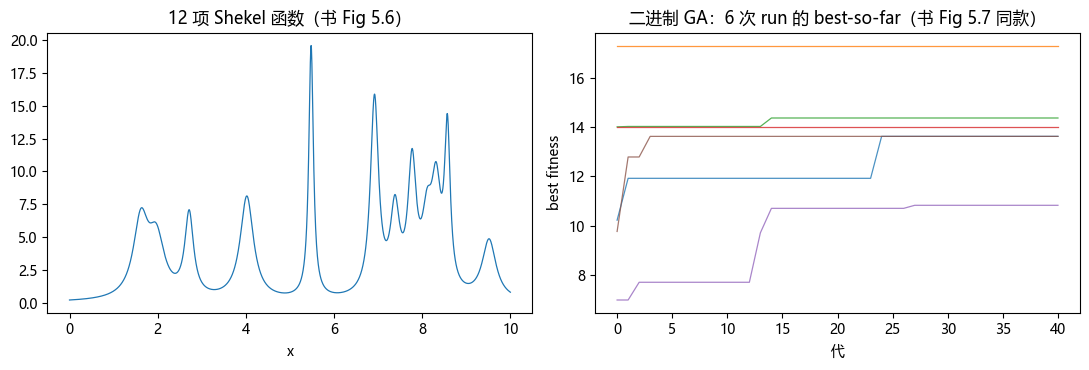

GA 6 run 终值: [13.624 17.308 14.369 14.01  10.828 13.624]


In [5]:
# ===== 书 §5.4 Table 5.1 Shekel =====
pars = np.array([[10.295,7.382,0.1613],[4.722,1.972,0.2327],[10.928,8.111,0.2047],
                 [11.052,2.714,0.1579],[3.820,4.022,0.1268],[12.911,5.480,0.0519],
                 [6.163,9.517,0.2204],[13.860,8.571,0.0838],[5.310,6.918,0.0665],
                 [4.047,1.618,0.1719],[8.085,7.771,0.1040],[7.974,8.316,0.1340]])
def shekel(x):
    x = np.asarray(x, float)
    return np.sum(1/(pars[:,0]*(x[..., None]-pars[:,1])**2 + pars[:,2]), axis=-1)
xs = np.linspace(0, 10, 2000)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(xs, shekel(xs), lw=0.9)
ax[0].set_title("12 项 Shekel 函数（书 Fig 5.6）"); ax[0].set_xlabel("x")
def ga_binary(gens=40, pop=12, pm=0.06):
    C = rng.integers(0, 1024, pop)
    fit = shekel(10*C/1023); best = fit.max(); hist = [best]
    for g in range(gens):
        w = fit/fit.sum()
        parents = rng.choice(pop, pop, p=w/w.sum())     # 轮盘赌
        kids = []
        for i in range(0, pop-1, 2):                    # 单点交叉
            k = int(rng.integers(1, 10))
            m1, m2 = 1<<10, (1<<10)-1
            mask = m1-1 ^ ((1<<k)-1)                    # 前 k 位
            a, b = C[parents[i]], C[parents[i+1]]
            kids.append((a & mask) | (b & ~mask & (m1-1)))
            kids.append((b & mask) | (a & ~mask & (m1-1)))
        kids = np.array(kids)
        mut = rng.random(len(kids)) < pm
        kids[mut] ^= 1 << rng.integers(0, 10, mut.sum())   # 位翻转
        C = kids; fit = shekel(10*C/1023)
        best = max(best, fit.max()); hist.append(best)
    return np.array(hist)
runs = np.array([ga_binary() for _ in range(6)])
for r in runs: ax[1].plot(r, lw=0.9, alpha=0.8)
ax[1].set_title("二进制 GA：6 次 run 的 best-so-far（书 Fig 5.7 同款）")
ax[1].set_xlabel("代"); ax[1].set_ylabel("best fitness")
plt.tight_layout(); save(fig, "out-5-4.png"); plt.show()
print(f"GA 6 run 终值: {runs[:, -1].round(3)}")

## 实验 5 实数编码 GA + 粒度交叉（书 §5.4）

变异 = 邻域均匀扰动；交叉 = grainsize 尾位交换（书 Fig 5.8 的算子）。

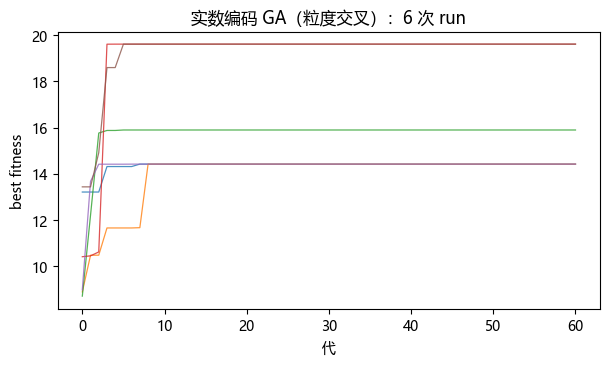

实数编码 6 run 终值: [14.414 14.413 15.895 19.621 14.414 19.622]；理论全局最优 ≈ 19.597


In [6]:
# ===== 书 §5.4 实数编码 =====
def ga_real(gens=60, pop=12, delta=0.25):
    P = rng.uniform(0, 10, pop)
    fit = shekel(P); best = fit.max(); hist = [best]
    for g in range(gens):
        w = fit/fit.sum()
        for _ in range(pop//2):                     # 变异并入
            i = rng.choice(pop, p=w/w.sum())
            kid = np.clip(P[i] + rng.uniform(-delta, delta), 0, 10)
            f2 = shekel(kid)
            if f2 > np.sort(fit)[0]:
                j = fit.argmin(); P[j], fit[j] = kid, f2
        for _ in range(pop//2):                     # 粒度交叉并入
            i1, i2 = rng.choice(pop, 2, p=(w/w.sum()))
            gg = rng.uniform(0.01, 1.0)
            tx, ty = gg*np.mod(P[i1], gg), gg*np.mod(P[i2], gg)
            x1 = np.clip(P[i1]-tx+ty, 0, 10); x2 = np.clip(P[i2]-ty+tx, 0, 10)
            f1b, f2b = shekel(x1), shekel(x2)
            j = fit.argmin()
            if max(f1b, f2b) > fit[j]:
                P[j] = x1 if f1b > f2b else x2; fit[j] = max(f1b, f2b)
        best = max(best, fit.max()); hist.append(best)
    return np.array(hist)
runs_r = np.array([ga_real() for _ in range(6)])
fig, ax = plt.subplots(figsize=(7, 3.6))
for r in runs_r: ax.plot(r, lw=0.9, alpha=0.8)
ax.set_title("实数编码 GA（粒度交叉）：6 次 run")
ax.set_xlabel("代"); ax.set_ylabel("best fitness")
save(fig, "out-5-5.png"); plt.show()
print(f"实数编码 6 run 终值: {runs_r[:, -1].round(3)}；理论全局最优 ≈ {shekel(xs).max():.3f}")

## 实验 6 permanent：精确计数 + GA（书 §5.5，Alg 5.1）

3:5 问题穷举验证最大值 2；GA（NSEW 变异 + templated 交叉）解 4:8，与穷举最优对照。

3:5 穷举 126 个矩阵：最大 permanent = 2（书 2）；分布 [45 72  9]


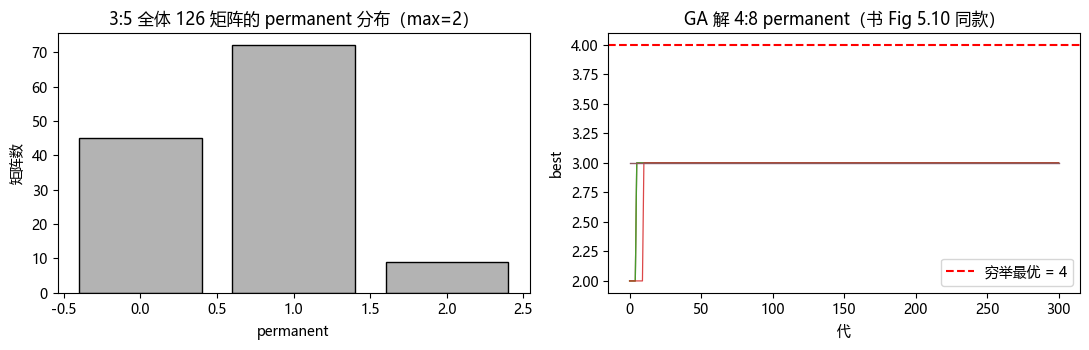

4:8 穷举最优 = 4；GA 6 run 终值 [3 3 3 3 3 3]


In [7]:
# ===== 书 §5.5 Alg 5.1 + GA =====
def perm_exact(mat):                      # 书 Alg 5.1 递归
    N = len(mat); used = [False]*N
    def rec(row):
        if row == N: return 1
        v = 0
        for j in range(N):
            if not used[j] and mat[row][j]:
                used[j] = True; v += rec(row+1); used[j] = False
        return v
    return rec(0)
# 3:5 穷举（C(9,5)=126）
best35, vals35 = 0, []
for ones in np.argwhere(np.ones((1,))).tolist():
    pass
from itertools import combinations
for cells_ in combinations(range(9), 5):
    m = np.zeros((3, 3), int)
    for c in cells_: m[c//3, c % 3] = 1
    v = perm_exact(m); vals35.append(v); best35 = max(best35, v)
print(f"3:5 穷举 126 个矩阵：最大 permanent = {best35}（书 2）；分布 {np.bincount(vals35)}")

# 4:8 GA
n, m_ones = 4, 8
def perm_ga(gens=300, pop=12):
    def randmat():
        idx = rng.choice(16, m_ones, replace=False)
        M = np.zeros((n, n), int); M[idx//n, idx % n] = 1; return M
    def nsew(M):                          # NSEW 邻域交换（wraparound）
        M = M.copy(); i, j = rng.integers(n), rng.integers(n)
        d = int(rng.integers(4)); di, dj = [(-1,0),(1,0),(0,-1),(0,1)][d]
        i2, j2 = (i+di) % n, (j+dj) % n
        M[i, j], M[i2, j2] = M[i2, j2], M[i, j]
        return M
    def cross(A, B):                      # templated global swap
        a, b = A.flatten().copy(), B.flatten().copy()
        st = int(rng.integers(16))
        diff01 = np.where((a == 0) & (b == 1))[0]
        diff10 = np.where((a == 1) & (b == 0))[0]
        if len(diff01) and len(diff10):
            p1 = diff01[(diff01 - st) % 16 == ((diff01 - st) % 16)][0] if False else None
            o1 = (diff01 - st) % 16; o2 = (diff10 - st) % 16
            i1_, i2_ = np.argmin(o1), np.argmin(o2)
            e1, e2 = diff01[i1_], diff10[i2_]
            a[e1], b[e1] = b[e1], a[e1]; a[e2], b[e2] = b[e2], a[e2]
        return a.reshape(n, n), b.reshape(n, n)
    P = [randmat() for _ in range(pop)]
    fit = [perm_exact(M) for M in P]
    best = max(fit); hist = [best]
    for g in range(gens):
        for _ in range(pop//4):                       # 变异
            i = int(rng.integers(pop)); k = randmat()
            M = nsew(P[i]); f2 = perm_exact(M)
            if f2 > min(fit):
                j = fit.index(min(fit)); P[j], fit[j] = M, f2
        for _ in range(pop//2):                       # 交叉
            i1, i2 = rng.integers(pop), rng.integers(pop)
            A, B = cross(P[i1], P[i2])
            fA = perm_exact(A)
            if fA > min(fit):
                j = fit.index(min(fit)); P[j], fit[j] = A, fA
        best = max(best, max(fit)); hist.append(best)
    return np.array(hist)
# 4:8 穷举最优（C(16,8)=12870，一次性算）
best48 = 0
for cells_ in combinations(range(16), 8):
    M = np.zeros((4, 4), int)
    for c in cells_: M[c//4, c % 4] = 1
    best48 = max(best48, perm_exact(M))
runs = np.array([perm_ga() for _ in range(6)])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(*np.unique(vals35, return_counts=True), color="0.7", edgecolor="k")
ax[0].set_title("3:5 全体 126 矩阵的 permanent 分布（max=2）")
ax[0].set_xlabel("permanent"); ax[0].set_ylabel("矩阵数")
for r in runs: ax[1].plot(r, lw=0.9, alpha=0.85)
ax[1].axhline(best48, ls="--", color="r", label=f"穷举最优 = {best48}")
ax[1].set_title("GA 解 4:8 permanent（书 Fig 5.10 同款）"); ax[1].legend()
ax[1].set_xlabel("代"); ax[1].set_ylabel("best")
plt.tight_layout(); save(fig, "out-5-6.png"); plt.show()
print(f"4:8 穷举最优 = {best48}；GA 6 run 终值 {runs[:, -1]}")

## 实验 7（实验 6 的第二部分：IIP 并行重启）

§5.3 的工程课：欺骗性景观上，8 条短重启 vs 1 条长 run。

同样 40,000 迭代预算内命中全局：单 run 0.0% vs 8 重启 100.0%


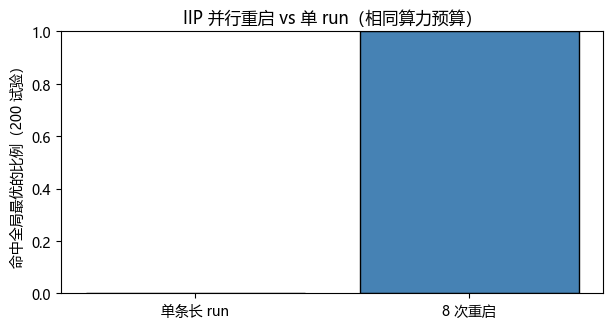

In [8]:
# ===== §5.3 IIP 重启 =====
def sa_short(n_iter):
    x = 9.0
    for t in range(1, n_iter+1):
        y = x + rng.normal(0, 0.4)
        if 0 <= y <= 10:
            T = 2.0*(0.9985**t) + 0.02
            if rng.random() < min(1, np.exp(-(fmult(y)-fmult(x))/T)): x = y
    return x
xstar = xs[fmult(xs).argmin()]
def success_time(n_iter_total, restarts, thresh=0.35):
    per = n_iter_total // max(restarts, 1); used = 0
    for _ in range(restarts):
        x = sa_short(per); used += per
        if abs(x - xstar) < 0.35: return used
    return n_iter_total
Ntot = 40_000
singles = np.array([success_time(Ntot, 1) < Ntot for _ in range(200)])
multi = np.array([success_time(Ntot, 8) < Ntot for _ in range(200)])
print(f"同样 40,000 迭代预算内命中全局：单 run {singles.mean():.1%} vs 8 重启 {multi.mean():.1%}")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(["单条长 run", "8 次重启"], [singles.mean(), multi.mean()],
       color=["0.6", "steelblue"], edgecolor="k")
ax.set_ylim(0, 1); ax.set_ylabel("命中全局最优的比例（200 试验）")
ax.set_title("IIP 并行重启 vs 单 run（相同算力预算）")
save(fig, "out-5-8.png"); plt.show()